# THIS HOMEWORK WAS BASED ON COURSE'S GITHUB. IT DOESN'T MATCH WITH ANY QUESTION OF THE FORMS 

In [250]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sns

In [251]:
# Import data

data = pd.read_csv('Telco_Churn.csv')

In [252]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [253]:
# Fomatting the data columns name

for col in data.columns:
    data = data.rename(columns= {col:col.lower()})

In [254]:
# Formattin values of categorical columns

categorical = data.dtypes[data.dtypes == 'object'].index

for cat in categorical:
    data[cat] = data[cat].map(lambda x: x.lower().replace(" ", "_"))

In [255]:
data.totalcharges = pd.to_numeric(data.totalcharges, errors= 'coerce')

In [256]:
# NaN Totalcharges

data[['customerid', 'totalcharges']][data['totalcharges'].isna()]

,customerid,totalcharges
488,4472-lvygi,NaN
753,3115-czmzd,NaN
936,5709-lvoeq,NaN
1082,4367-nuyao,NaN
1340,1371-dwpaz,NaN
3331,7644-omvmy,NaN
3826,3213-vvolg,NaN
4380,2520-sgtta,NaN
5218,2923-arzlg,NaN
6670,4075-wkniu,NaN


In [257]:
# filling NaN

data = data.fillna(0)

In [258]:
# Categorical and numerical variables

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

numerical = ['tenure', 'totalcharges', 'monthlycharges']

In [259]:
# Encoding churn column 0 = No, 1 = Yes

data['churn'] = data['churn'].astype('category').cat.codes

In [260]:
# Setting category for all categorical variables

for cat in categorical:
    data[cat] = data[cat].astype('category')

In [261]:
# Encoding all categorical variables

encoder = OneHotEncoder(handle_unknown= 'ignore', sparse_output= False)
dummies = encoder.fit_transform(data[categorical])

dummies = pd.DataFrame(data = dummies, columns = encoder.get_feature_names_out(categorical), index = data.index)
dummies.head()

,gender_female,gender_male,seniorcitizen_0,seniorcitizen_1,partner_no,partner_yes,dependents_no,dependents_yes,phoneservice_no,phoneservice_yes,multiplelines_no,multiplelines_no_phone_service,multiplelines_yes,internetservice_dsl,internetservice_fiber_optic,internetservice_no,onlinesecurity_no,onlinesecurity_no_internet_service,onlinesecurity_yes,onlinebackup_no,onlinebackup_no_internet_service,onlinebackup_yes,deviceprotection_no,deviceprotection_no_internet_service,deviceprotection_yes,techsupport_no,techsupport_no_internet_service,techsupport_yes,streamingtv_no,streamingtv_no_internet_service,streamingtv_yes,streamingmovies_no,streamingmovies_no_internet_service,streamingmovies_yes,contract_month-to-month,contract_one_year,contract_two_year,paperlessbilling_no,paperlessbilling_yes,paymentmethod_bank_transfer_(automatic),paymentmethod_credit_card_(automatic),paymentmethod_electronic_check,paymentmethod_mailed_check
0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [262]:
# Assembling the dummies with the dataframe

data = pd.concat([data, dummies], axis = 1)

In [263]:
# Split data

data_fulltrain, data_test = train_test_split(data, test_size= 0.2, random_state= 14)
data_train, data_val = train_test_split(data_fulltrain, test_size= 0.25, random_state= 15)

In [264]:
print(len(data_train), len(data_test), len(data_val))

4225 1409 1409


In [265]:
# Checking the number of categories

data_fulltrain[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

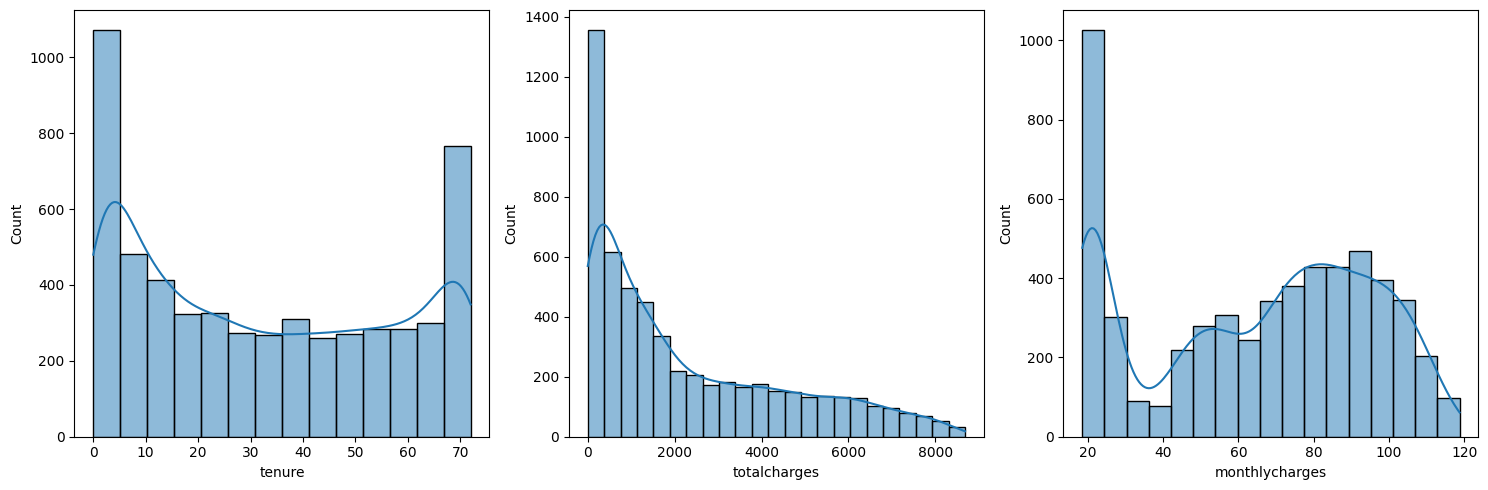

In [266]:
# Checking distribution of numerical variables

fig, ax = plt.subplots(1,3, figsize= (15,5))

columns = [
    ('tenure', ax[0]),
    ('totalcharges', ax[1]),
    ('monthlycharges', ax[2])
]

for col, ax in columns:
    sns.histplot(data_fulltrain[col], kde= True, ax = ax)

plt.tight_layout()
plt.show()

In [267]:
print(f'total charges bound: ({data_fulltrain['totalcharges'].min()}, {data_fulltrain['totalcharges'].max()})\n monthly charges: ({data_fulltrain['monthlycharges'].min()}, {data_fulltrain['monthlycharges'].max()})')

total charges bound: (0.0, 8684.8)
 monthly charges: (18.55, 118.75)


¿ What's the plan most of new users buy?

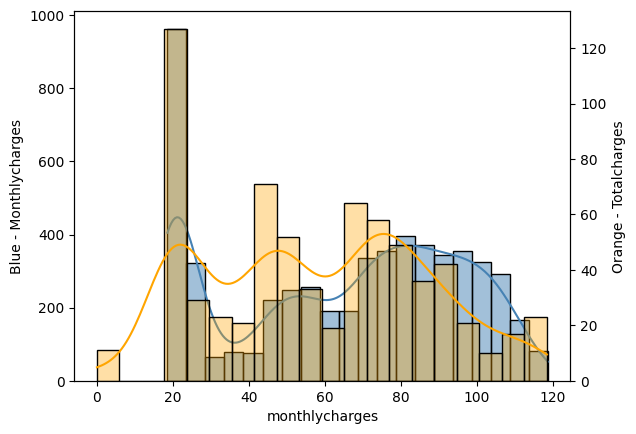

In [268]:
a = data_fulltrain['totalcharges'][data_fulltrain['totalcharges']<=118.75]
b = data_fulltrain['monthlycharges']

fig, ax1 = plt.subplots()

sns.histplot(b, kde= True, ax= ax1, bins= 20, color= "SteelBlue")
ax1.set_ylabel('Blue - Monthlycharges')

ax2 = ax1.twinx()
sns.histplot(a, alpha= 0.35, kde = True, ax= ax2, color= 'Orange', bins= 20)
ax2.set_ylabel('Orange - Totalcharges')

plt.show()

Assuming monthy charges is the mean charge a user make each month.
The people who have charged 20-120$ in total are new ones. Total charge of new people (~160 users) fit with the first peak of monthly charge (~1200 users). It means people who recently signed up Telco services, have hired cheapest plan (basic plan).

The graph also suggest these new users tilt to buy more expensive plans (70 -110$)

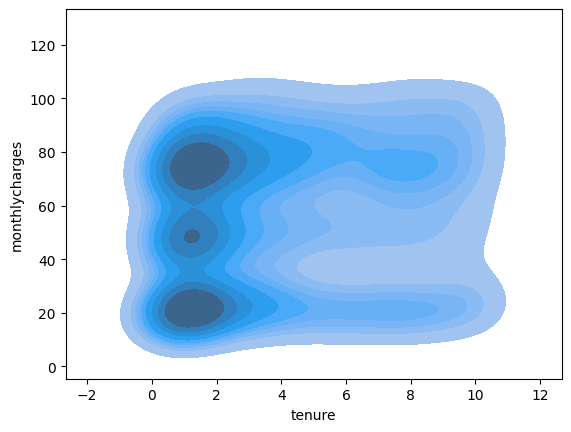

In [269]:
a = data_fulltrain['monthlycharges']
b = data_fulltrain['tenure'][data_fulltrain['tenure']<11] # People with less than 6 months of teanure are new users

sns.kdeplot(x=b,y =a, fill = True)
plt.show()

This graph confirms what the previous graph was suggesting. New users tilt to but whether cheapest plan or more expensive plans since we can see 2 separate dark dots (lied on 20 and 80 monthly charges axis) in users who have signed up the service 0-2 months

In [270]:
print(f'total charges bound: ({data_fulltrain['tenure'].min()}, {data_fulltrain['tenure'].max()})')

total charges bound: (0, 72)


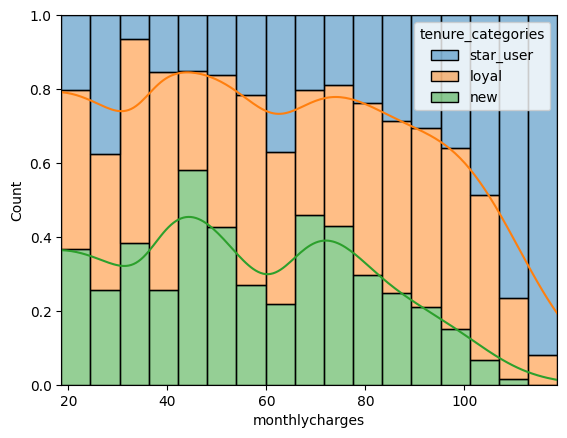

In [271]:
a = pd.cut(data['tenure'], bins= [0, 11, 51, 73], labels = ["new", 'loyal', 'star_user'])
b = data_fulltrain['monthlycharges']

sns.histplot(data = pd.DataFrame({'tenure_categories': a, 'monthlycharges': b}), x= 'monthlycharges', hue = 'tenure_categories', hue_order= ['star_user', 'loyal', 'new'], kde = True, multiple= 'fill')
plt.show()

This graph confirms the trend. New users tilt to choose less expensive plans. As we can see, there're three peaks in monthly charges among new users, but two of them are confirmed by the previous graphs. Those are: 20$ plans, 70 - 80$ plans

Does Tenure affect churn rate?

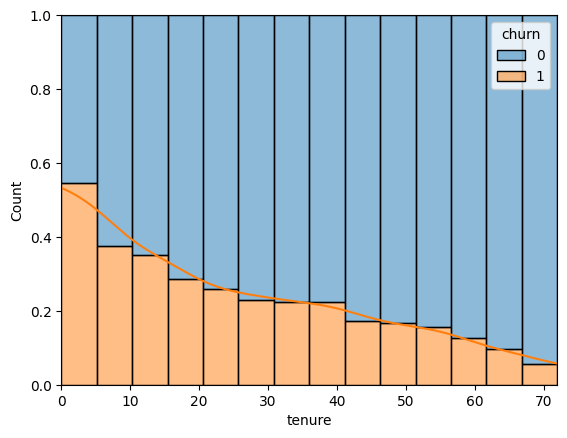

In [272]:
sns.histplot(data_fulltrain, x= 'tenure', hue= 'churn', multiple= 'fill', kde= True)
plt.show()

Why does new users are more likely to churn?

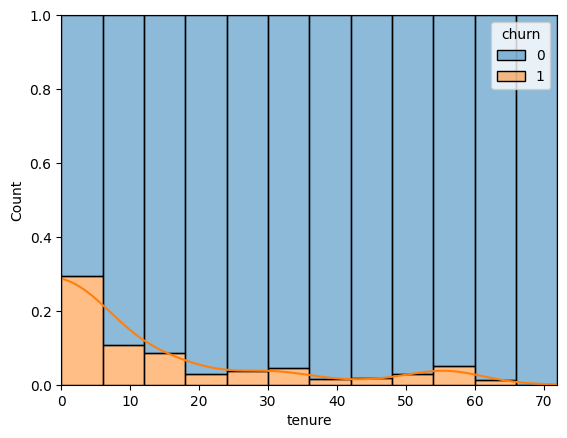

In [273]:
sns.histplot(data_fulltrain[data_fulltrain['monthlycharges']<30], x= 'tenure', hue= 'churn', multiple= 'fill', kde= True)
plt.show()

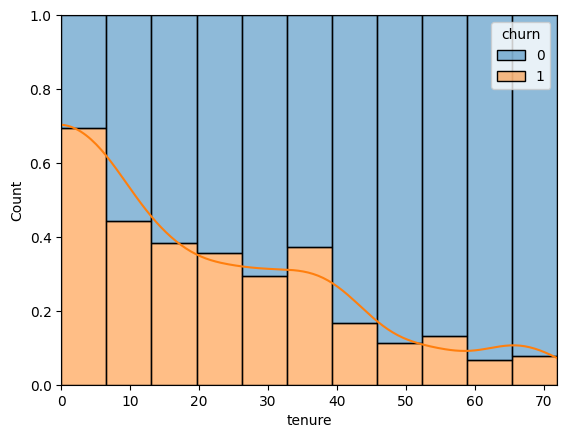

In [274]:
sns.histplot(data_fulltrain[(data_fulltrain['monthlycharges']<81)*(data_fulltrain['monthlycharges']>70)], x= 'tenure', hue= 'churn', multiple= 'fill', kde= True)
plt.show()

MAIN INSIGHT: Since we know most of new users hire cheapest plan or slightly more expensive one, we compare both and the results are that new users who hire more expensive plans tilt to churn more than users who hire cheapest plan. Probably their high expectatiosn are not met at all. We should consider Tenure and Monthly for the model, but probably they're correlated, we should check that

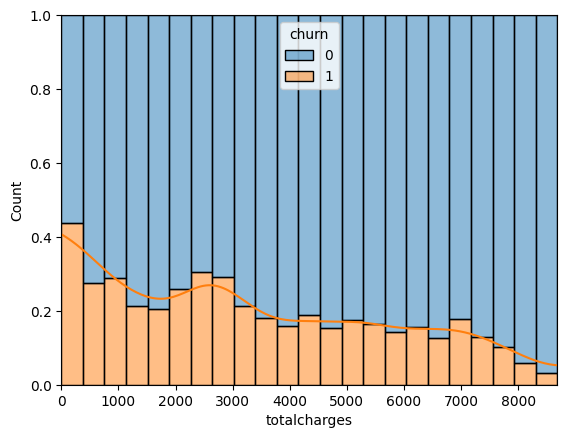

In [275]:
sns.histplot(data_fulltrain, x = 'totalcharges', hue= 'churn', multiple= 'fill', kde= True)
plt.show()

As we can see, total charge confirm the hypothesis new users (small total charge) tilt to churn more than older users (high total charge)

In [276]:
# Checking max and min of monthly charge

print (f'max: {data_fulltrain.monthlycharges.max()}, min: {data_fulltrain.monthlycharges.min()}')

max: 118.75, min: 18.55


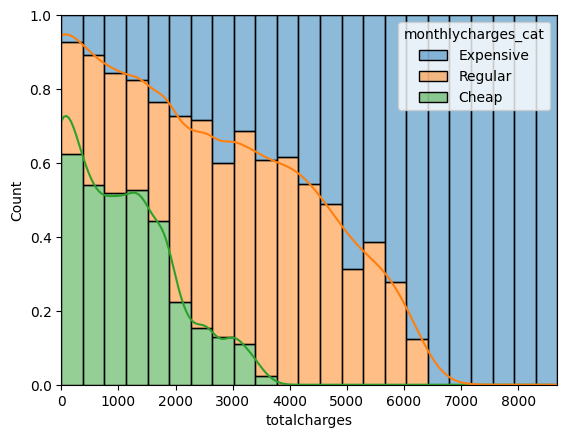

In [277]:
a = pd.cut(data_fulltrain['monthlycharges'], bins= 3, labels = ["Cheap", 'Regular', 'Expensive'])
b = data_fulltrain['totalcharges']

sns.histplot(data = pd.DataFrame({'monthlycharges_cat': a, 'totalcharges': b}), x= 'totalcharges', hue = 'monthlycharges_cat', hue_order= ['Expensive', 'Regular', 'Cheap'], kde = True, multiple= 'fill')
plt.show()

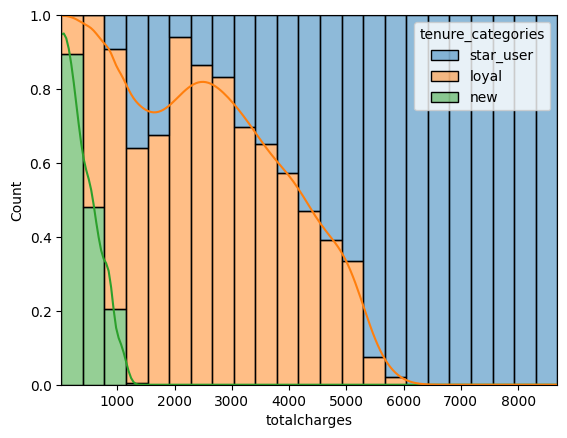

In [278]:
a = pd.cut(data_fulltrain['tenure'], bins= [0, 11, 51, 120], labels = ["new", 'loyal', 'star_user'])
b = data_fulltrain['totalcharges']

sns.histplot(data = pd.DataFrame({'tenure_categories': a, 'totalcharges': b}), x= 'totalcharges', hue = 'tenure_categories', hue_order= ['star_user', 'loyal', 'new'], kde = True, multiple= 'fill')
plt.show()

The shape of both graphs are similar. So, that means people who are new (small amount of total charge) tilt to get cheapest plan or regular plan.

In [279]:
a = pd.cut(data_fulltrain['monthlycharges'], bins= 3, labels = ["Cheap", 'Regular', 'Expensive'])
b = pd.cut(data_fulltrain['tenure'], bins= [0, 11, 51, 120], labels = ["new", 'loyal', 'star_user'])

df_1 = pd.DataFrame({'monthlycharges_cat': a, 'tenure_cat': b})

round(pd.crosstab(a,b, normalize= 'columns'),2)

tenure,new,loyal,star_user
monthlycharges,,,
Cheap,0.46,0.34,0.24
Regular,0.40,0.35,0.29
Expensive,0.15,0.31,0.47


MAIN INSIGHT: These thre graphs confirms our hypothesis that new users tilt to hire cheap (20$ monthly) or regular services (70 - 80$ monthly), but we can also add that star users hire expensive services, probably because they already got enough confidence by the company since they have stayed with them for a long time. So, totalcharge variable help us to reinforce the idea of people who hired the service for a small period tilt to churn since an fail expectation meetings (new users who hired regular plans) or because they hired other better option (new users who hired cheap plans). This variable should evaluated in order to check the correlation with the rest of variable to avoid collinearity

In [280]:
data_corr = data_fulltrain[numerical].corr()
data_corr.style.background_gradient(gmap= data_corr.abs(), vmin= 0, vmax = 1, axis= None)

,tenure,totalcharges,monthlycharges
tenure,1.000000,0.825916,0.251530
totalcharges,0.825916,1.000000,0.653614
monthlycharges,0.251530,0.653614,1.000000


The reason tenure and monthly charge has a low correlation is by the fact that there're multiple clusters in each interval of tenure (i.e: Clusters of charges among new users of third graph)

It's advisable to use only Tenure and Monthlycharges to avoid collinearity

In [281]:
data[numerical].corrwith(data_fulltrain.churn)

tenure           -0.349644
totalcharges     -0.198066
monthlycharges    0.190238
dtype: float64

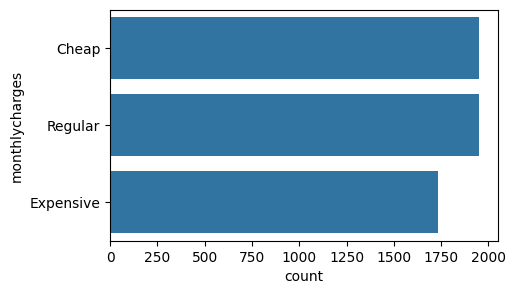

In [282]:
a = pd.cut(data_fulltrain['monthlycharges'], bins= 3, labels = ["Cheap", 'Regular', 'Expensive'])


plt.figure(figsize= (5,3))
sns.countplot(a)
plt.show()

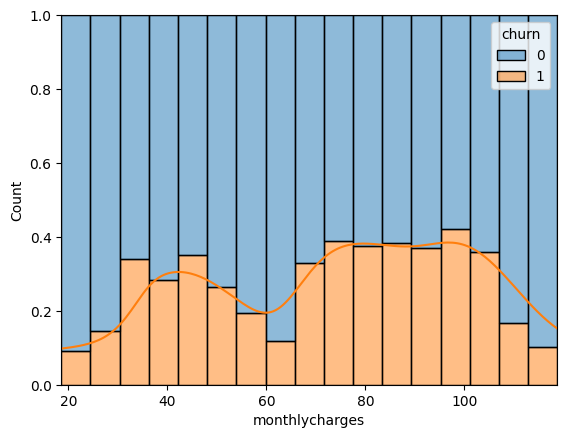

In [283]:
sns.histplot(data= data_fulltrain, x= 'monthlycharges', hue = 'churn', multiple = 'fill', kde= True)
plt.show()

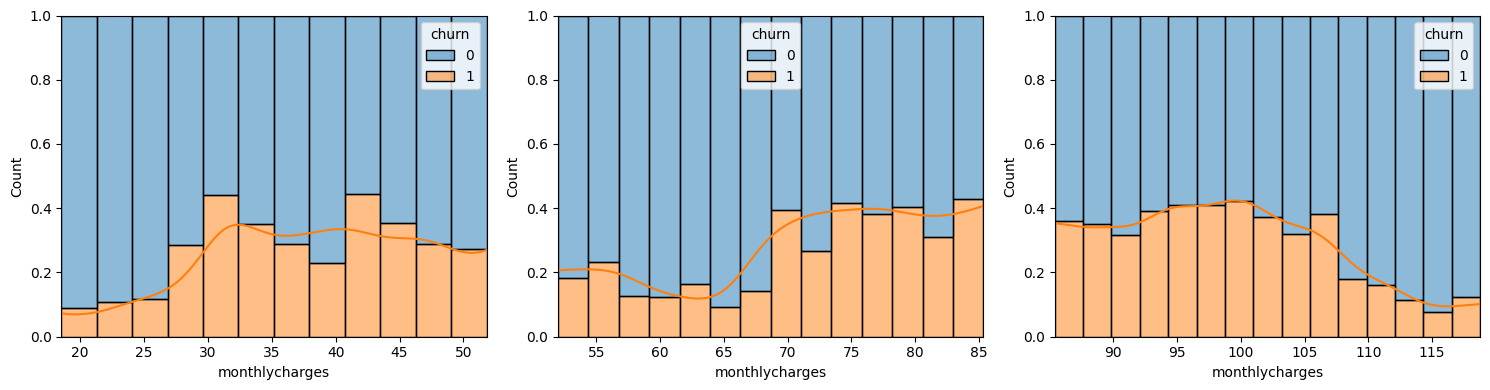

In [284]:
a = pd.cut(data_fulltrain['monthlycharges'], bins= 3, labels = ["Cheap", 'Regular', 'Expensive'])
b = data['monthlycharges']
c = data['churn']

abc = pd.DataFrame({'monthlycharges_cat': a, 'monthlycharges': b, 'churn': c})

fig, ax = plt.subplots(1, 3, figsize = (15,4))

plots = [
    ('Cheap', ax[0]),
    ('Regular', ax[1]),
    ('Expensive', ax[2])
]

for cat, axs in plots:
    sns.histplot(data = abc[abc.monthlycharges_cat == cat], hue= 'churn',x = 'monthlycharges', kde = True, multiple= 'fill', ax = axs)

plt.tight_layout()
plt.show()

These two last graphs confirms why Monthly charge means as you pay more, you're more likely to churn. Most of the users pay cheap or regular plans. So, if we check the trend of churn in boths categories we'll face that is more likely to churn if you pay more. This relates with the previous insight about new users who don't meet their expectations with regular plans. there's something bad with regular plans. I don't think cheap plans are bad at all because these plans are not the best always, considering the whole indrustry.

In [285]:
global_churn = data_fulltrain.churn.mean()
global_churn

np.float64(0.2701455449059283)

In [286]:
for cat in categorical:

    df_group = data_fulltrain.groupby(cat).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['ratio'] = df_group['mean'] / global_churn

    print(f'====== {cat} ======')
    display(df_group)

====== gender ======


C:\Users\USER\AppData\Local\Temp\ipykernel_19692\3363005027.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_group = data_fulltrain.groupby(cat).churn.agg(['mean', 'count'])


,mean,count,diff,ratio
gender,,,,
female,0.270011,2811,-0.000135,0.999501
male,0.270280,2823,0.000134,1.000497


====== seniorcitizen ======


C:\Users\USER\AppData\Local\Temp\ipykernel_19692\3363005027.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_group = data_fulltrain.groupby(cat).churn.agg(['mean', 'count'])


...

C:\Users\USER\AppData\Local\Temp\ipykernel_19692\3363005027.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_group = data_fulltrain.groupby(cat).churn.agg(['mean', 'count'])


,mean,count,diff,ratio
paperlessbilling,,,,
no,0.166159,2299,-0.103986,0.615073
yes,0.341829,3335,0.071684,1.265352


C:\Users\USER\AppData\Local\Temp\ipykernel_19692\3363005027.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_group = data_fulltrain.groupby(cat).churn.agg(['mean', 'count'])


====== paymentmethod ======


,mean,count,diff,ratio
paymentmethod,,,,
bank_transfer_(automatic),0.173486,1222,-0.096659,0.642195
credit_card_(automatic),0.145215,1212,-0.124931,0.537542
electronic_check,0.460242,1899,0.190097,1.703682
mailed_check,0.199846,1301,-0.070299,0.739773


After these tables, we can discard some variables which have low difference between categories. "Gender", "Phone service" and "Multiplelines". In fact people who don't have internet service are more likely to stay with the service.

In [287]:
# Measuring the mutual information of categorial variables

cat_mutinfo = {}

for cat in categorical:
    mut_inf = mutual_info_score(data_fulltrain.churn,data_fulltrain[cat])
    cat_mutinfo[cat] = round(mut_inf,6)

cat_mutinfo = pd.DataFrame(cat_mutinfo, index = ['mutual_information']).T
cat_mutinfo.sort_values('mutual_information',ascending=False)

,mutual_information
contract,0.098025
onlinesecurity,0.066861
techsupport,0.063731
internetservice,0.054263
onlinebackup,0.048257
paymentmethod,0.046135
deviceprotection,0.045364
streamingtv,0.032860
streamingmovies,0.032856
paperlessbilling,0.019713


In [288]:
# Cleaning categorical variables

# Removing categorical variables

data = data.drop(columns = categorical)

In [289]:
# Split data

data_fulltrain, data_test = train_test_split(data, test_size= 0.2, random_state= 14)
data_train, data_val = train_test_split(data_fulltrain, test_size= 0.25, random_state= 15)

In [290]:
print(len(data_fulltrain), len(data_test), len(data_val))

5634 1409 1409


In [291]:
x_train = data_train.drop(columns=['customerid', 'churn'])
y_train = data_train['churn']

In [292]:
# Building the model

model = LogisticRegression(solver= 'lbfgs')

model.fit(x_train, y_train)

c:\Users\USER\Documents\Programación\PyP_Env\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [296]:
x_val = data_val.drop(columns=['customerid', 'churn'])
y_val = data_val['churn']

In [303]:
y_pred = model.predict_proba(x_val)[:,1]

In [305]:
churn_decision = (y_pred>=0.5)

In [308]:
(y_val == churn_decision).mean()

np.float64(0.7991483321504613)

In [ ]:
# Checking coefficients

coef = model.coef_[0].round(3)
variables = data_val.drop(columns=['customerid', 'churn']).columns

pd.DataFrame(dict(zip(variables, coef)), index= ['Coef']).T

,Coef
tenure,-0.062
monthlycharges,0.003
totalcharges,0.000
gender_female,-0.084
gender_male,-0.016
seniorcitizen_0,-0.262
seniorcitizen_1,0.162
partner_no,-0.011
partner_yes,-0.090
dependents_no,0.098


In [321]:
variables = ['tenure', 'monthlycharges', 'contract_month-to-month', 'contract_one_year', 'contract_two_year']

x_train = data_train[variables]
y_train = data_train['churn']

model2 = LogisticRegression(solver= 'lbfgs')
model2.fit(x_train, y_train)

LogisticRegression()

In [330]:
x_val = data_val[variables]
y_val = data_val['churn']

y_pred = model2.predict_proba(x_val)[:,1]

In [332]:
churn_decision = (y_pred >= 0.5)

In [334]:
acuraccy = (churn_decision == y_val).mean()
acuraccy

np.float64(0.7792760823278921)

In [335]:
# Checking coefficients

coef = model.coef_[0].round(3)
variables = data_val[variables].columns

pd.DataFrame(dict(zip(variables, coef)), index= ['Coef']).T

,Coef
tenure,-0.062
monthlycharges,0.003
contract_month-to-month,0.000
contract_one_year,-0.084
contract_two_year,-0.016


In [336]:
x_ftrain = data_fulltrain.drop(columns=['customerid', 'churn'])
y_ftrain = data_fulltrain['churn']

In [337]:
# Building the final model

model = LogisticRegression(solver= 'lbfgs')

model.fit(x_ftrain, y_ftrain)

c:\Users\USER\Documents\Programación\PyP_Env\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [338]:
x_test = data_test.drop(columns=['customerid', 'churn'])
y_test = data_test['churn']

In [339]:
y_pred = model.predict_proba(x_test)[:,1]

In [340]:
churn_decision = (y_pred >= 0.5)

In [341]:
accuracy = (churn_decision == y_test).mean()
accuracy

np.float64(0.8204400283889283)